# CyberSec Data Visualization — Numerical & Time Series

This lab uses a **provided synthetic CSV** (no generation code here) to practice **data visualization** in a network-security context.

## Learning Outcomes
After completing this notebook, you should be able to:
1. Visualize **class balance** and explain why imbalance matters for modeling and evaluation.
2. Explore **numerical distributions** and compare them **by class** to identify separability.
3. Inspect **feature relationships** (scatter) and **correlations** (heatmap) to inform feature selection.
4. Build **time-series** visualizations (per-minute counts; rolling averages) to surface spikes and trends.

## 0. Setup (Load the Provided CSV)

> Replace `DATA_PATH` with your local path (e.g., `cicids_synthetic_dataset.csv`).  
> If you see `FileNotFoundError`, verify the path and working directory.

**Why this matters:** Loading data correctly is the first step of any analysis. Using a pre-generated CSV keeps your focus on visualization rather than data creation.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 120)
pd.set_option('display.width', 160)

%matplotlib inline

# === STUDENT ACTION ===
DATA_PATH = "path2yourcsv"  # change if needed
df = pd.read_csv(DATA_PATH)
df.head(5)

,Timestamp,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,Packet Length Mean,Flow IAT Mean,Protocol,Label
0,2017-06-23 09:00:01,11432.267756,144,210,297.578495,10775.203588,TCP,BENIGN
1,2017-06-23 09:00:05,5231.925982,151,98,93.381647,1582.450279,TCP,BENIGN
2,2017-06-23 09:00:11,15252.153919,282,127,492.269758,3362.439221,UDP,Attack
3,2017-06-23 09:00:16,18494.302015,207,76,323.049609,8207.423055,UDP,BENIGN
4,2017-06-23 09:00:21,4586.575504,75,114,483.586073,15106.127239,TCP,BENIGN


## 1. Data Audit & Cleaning

**Purpose:** Ensure data quality before plotting. Visualizations are only as trustworthy as the underlying data.

**What we will do and why:**
- **Preview structure**: shapes, column names, and datatypes → confirm expectations and catch obvious issues.
- **Parse timestamps**: required for resampling/aggregation on time; malformed entries are removed.
- **Handle numerics**: coerce to numeric, replace inf with NaN, median-impute where necessary → robust stats.
- **Drop duplicates**: avoid double-counting and inflated trends.
- **Create minute bucket**: `df['Minute']` for per-minute time-series aggregation.


In [2]:
print("Shape:", df.shape)
print("\nColumns:", list(df.columns))
print("\nDtypes:"); print(df.dtypes)

# Parse timestamps and drop invalid rows
df['Timestamp'] = pd.to_datetime(df['Timestamp'], errors='coerce')
df = df.dropna(subset=['Timestamp']).copy()

# Clean numeric columns (coerce, remove inf, fill NaN with median)
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors='coerce')
    df[c].replace([np.inf, -np.inf], np.nan, inplace=True)
    if df[c].isna().any():
        df[c].fillna(df[c].median(), inplace=True)

# Deduplicate & create minute bucket
df.drop_duplicates(inplace=True)
df['Minute'] = df['Timestamp'].dt.floor('min')

print("\nBasic completeness check (missing values):")
print(df.isna().sum().sort_values(ascending=False).head(10))

print("\nLabel distribution (counts):")
print(df['Label'].value_counts())
df.head(3)

Shape: (10000, 8)

Columns: ['Timestamp', 'Flow Duration', 'Tot Fwd Pkts', 'Tot Bwd Pkts', 'Packet Length Mean', 'Flow IAT Mean', 'Protocol', 'Label']

Dtypes:
Timestamp              object
Flow Duration         float64
Tot Fwd Pkts            int64
Tot Bwd Pkts            int64
Packet Length Mean    float64
Flow IAT Mean         float64
Protocol               object
Label                  object
dtype: object

Basic completeness check (missing values):
Timestamp             0
Flow Duration         0
Tot Fwd Pkts          0
Tot Bwd Pkts          0
Packet Length Mean    0
Flow IAT Mean         0
Protocol              0
Label                 0
Minute                0
dtype: int64

Label distribution (counts):
Label
BENIGN    7004
Attack    2996
Name: count, dtype: int64


/var/folders/j1/_9hp2hq94_57pgt5bynvv_7r0000gp/T/ipykernel_95950/3326880829.py:13: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[c].replace([np.inf, -np.inf], np.nan, inplace=True)


,Timestamp,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,Packet Length Mean,Flow IAT Mean,Protocol,Label,Minute
0,2017-06-23 09:00:01,11432.267756,144,210,297.578495,10775.203588,TCP,BENIGN,2017-06-23 09:00:00
1,2017-06-23 09:00:05,5231.925982,151,98,93.381647,1582.450279,TCP,BENIGN,2017-06-23 09:00:00
2,2017-06-23 09:00:11,15252.153919,282,127,492.269758,3362.439221,UDP,Attack,2017-06-23 09:00:00


## 2. Class Balance — Bar Chart

**Why this plot?**  
- Shows **imbalance** between `BENIGN` and `Attack` classes.
- **So what?** Class imbalance affects **model training** (e.g., bias toward majority), **evaluation** (accuracy becomes misleading), and may require **stratified splits**, **class weights**, or **resampling** strategies.
**How to read it:** Taller bar = more samples of that class.


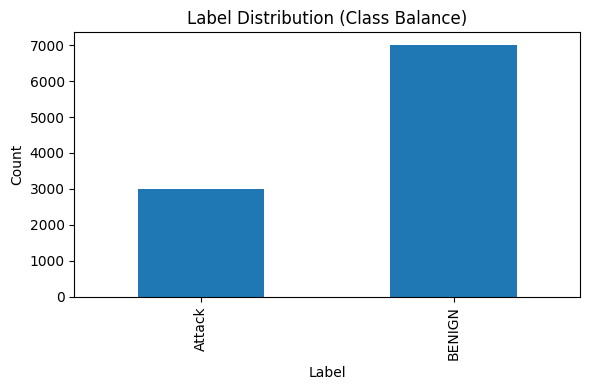

In [3]:
label_counts = df['Label'].value_counts().sort_index()
plt.figure(figsize=(6,4))
label_counts.plot(kind='bar')
plt.title('Label Distribution (Class Balance)')
plt.xlabel('Label'); plt.ylabel('Count')
plt.tight_layout(); plt.show()

## 3. Numerical Distributions — Histograms & Box Plots

**Why these plots?**
- **Histograms**: reveal **shape** (skewness, heavy tails), **central tendency**, and **outliers** per feature.
- **Box plots by class**: quick **side-by-side comparison** of distributions for `Attack` vs `BENIGN` to gauge **separability**.

**How to read them:**
- Histogram bars reflect frequency of values within bins.
- Box plot shows median (line), IQR (box), whiskers (range), and potential outliers (points). A visible shift between classes suggests discriminatory power.


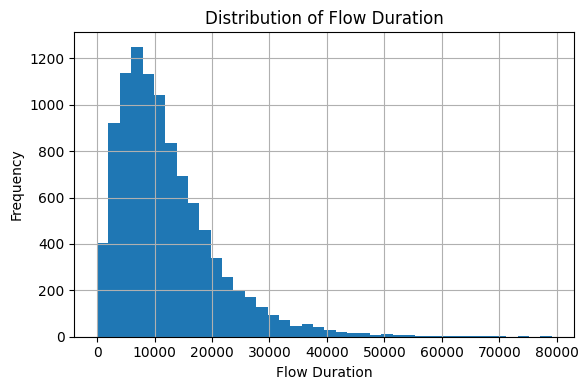

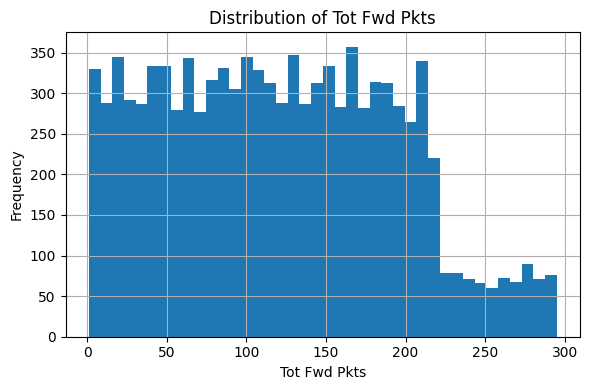

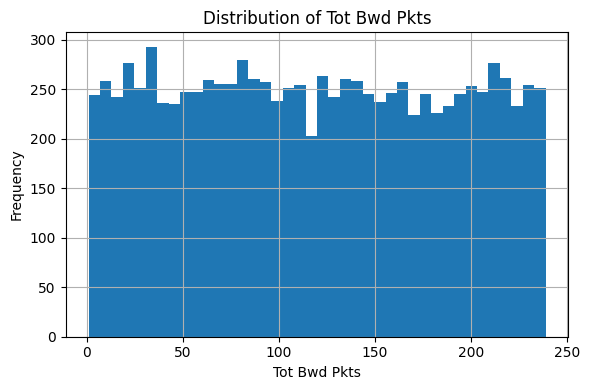

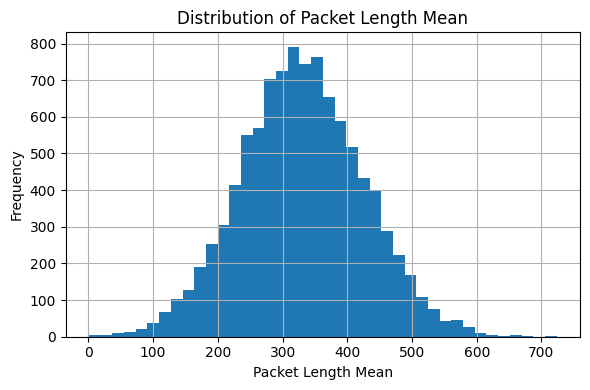

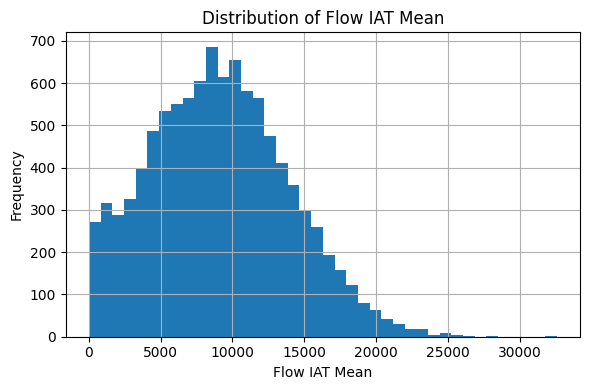

<Figure size 600x400 with 0 Axes>

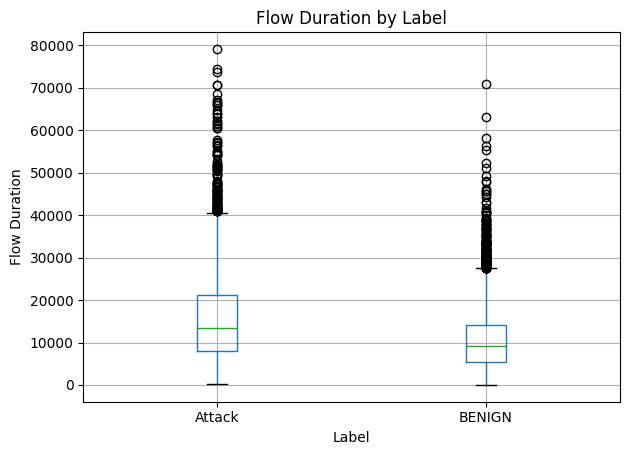

In [4]:
preferred = ['Flow Duration','Tot Fwd Pkts','Tot Bwd Pkts','Packet Length Mean','Flow IAT Mean']
plot_cols = [c for c in preferred if c in df.columns]

# Histograms for each selected feature
for c in plot_cols:
    plt.figure(figsize=(6,4))
    df[c].hist(bins=40)
    plt.title(f'Distribution of {c}')
    plt.xlabel(c); plt.ylabel('Frequency')
    plt.tight_layout(); plt.show()

# Box plot by label for the first available feature
if plot_cols:
    c = plot_cols[0]
    plt.figure(figsize=(6,4))
    df.boxplot(column=c, by='Label')
    plt.title(f'{c} by Label'); plt.suptitle('')
    plt.xlabel('Label'); plt.ylabel(c)
    plt.tight_layout(); plt.show()

## 4. Feature vs Feature — Scatter Plot

**Why this plot?**
- Checks **relationships** between two features (linear trend? clusters?).
- Colored by `Label` to see whether regions of feature space are dominated by `Attack` or `BENIGN` → suggests **separability** for classification.

**How to read it:**
- Each point is an observation. Overlaps indicate mixed classes; clean separation hints at useful features.


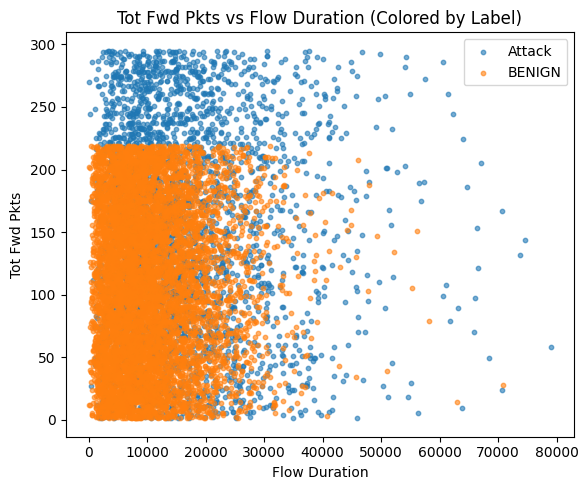

In [5]:
if len(plot_cols) >= 2:
    xcol, ycol = plot_cols[:2]
    plt.figure(figsize=(6,5))
    for lab, grp in df.groupby('Label'):
        plt.scatter(grp[xcol], grp[ycol], s=10, alpha=0.6, label=str(lab))
    plt.title(f'{ycol} vs {xcol} (Colored by Label)')
    plt.xlabel(xcol); plt.ylabel(ycol)
    plt.legend(); plt.tight_layout(); plt.show()
else:
    print("Not enough numeric columns for a scatter plot.")

## 5. Correlation Heatmap — Top Numeric Features

**Why this plot?**
- Highlights **redundant** features (high correlation) which may **inflate model complexity** without adding signal.
- Reveals **unexpected relationships** that can inspire **feature engineering**.

**How to read it:**
- Cells close to +1 / -1 mean strong positive/negative correlation. Near 0 means weak linear relationship.


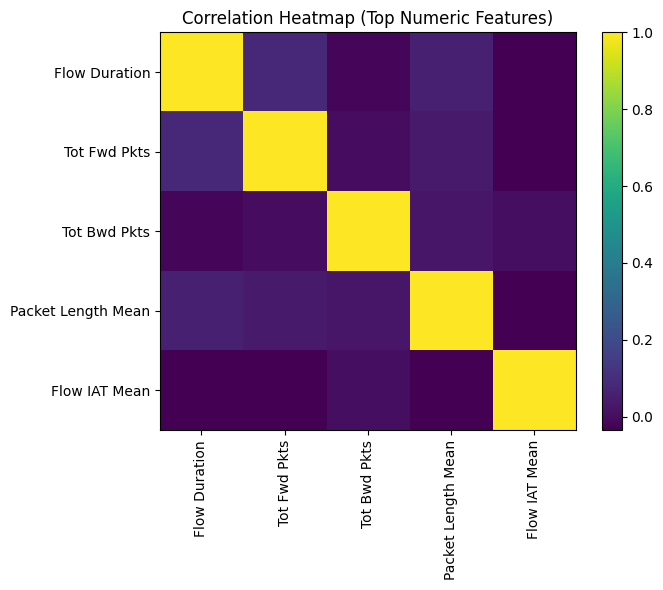

In [6]:
use_cols = [c for c in df.select_dtypes(include=[np.number]).columns if df[c].var() > 0][:15]
if use_cols:
    corr = df[use_cols].corr(numeric_only=True)
    plt.figure(figsize=(7,6))
    plt.imshow(corr.values, aspect='auto')
    plt.xticks(range(len(use_cols)), use_cols, rotation=90)
    plt.yticks(range(len(use_cols)), use_cols)
    plt.title('Correlation Heatmap (Top Numeric Features)')
    plt.colorbar(); plt.tight_layout(); plt.show()
else:
    print("No numeric features with variance for correlation heatmap.")

## 6. Time Series — Per-Minute Counts & Rolling Averages

**Why these plots?**
- **Per-minute counts**: show **traffic volume** and **spikes** that may indicate attacks (e.g., DoS bursts).
- **Per-minute counts by class**: compare **Attack vs BENIGN** dynamics over time.
- **Rolling average**: smooths short-term volatility to reveal **trend** (useful for monitoring/alerting thresholds).

**How to read them:**
- Spikes suggest sudden bursts of activity. If spikes align with `Attack` lines, it supports an anomaly/attack hypothesis.
- A rising rolling mean may indicate sustained high activity patterns.


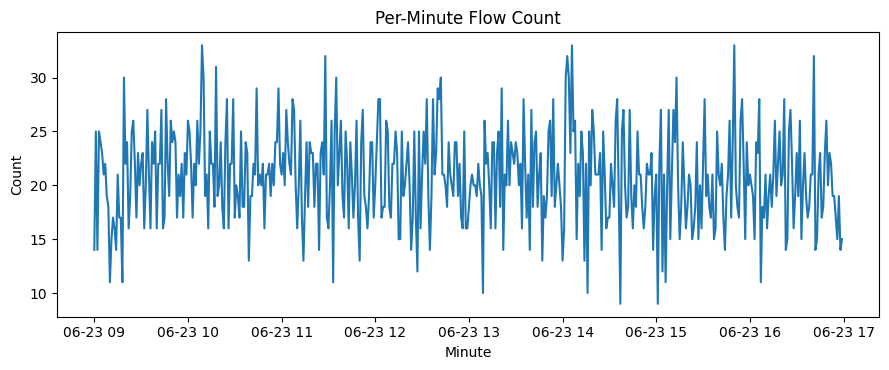

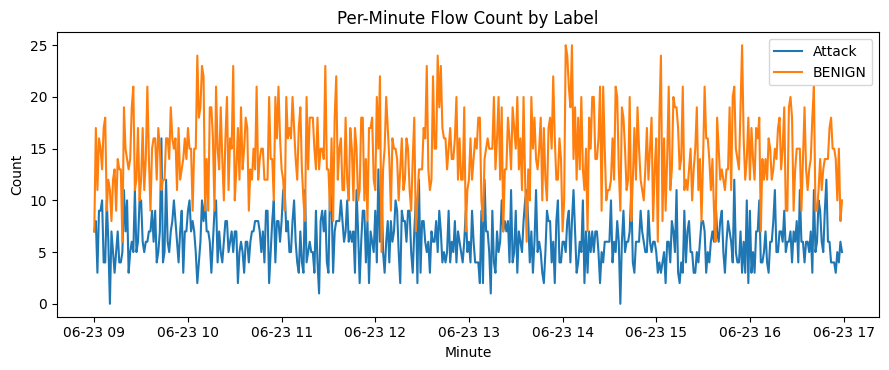

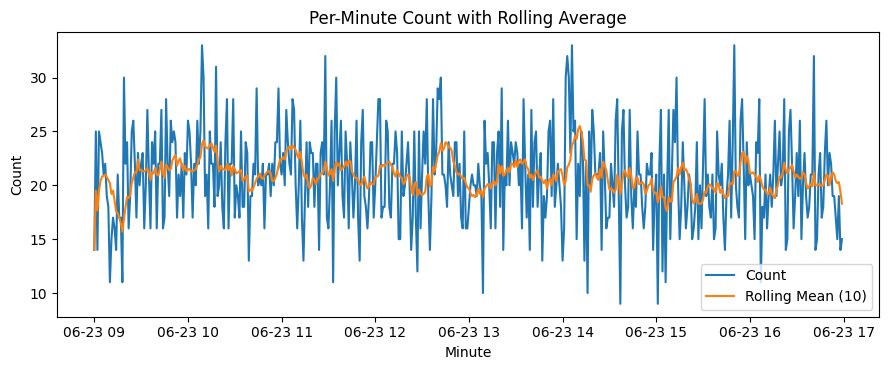

In [7]:
# Per-minute total flow count
per_min = df.groupby('Minute').size().rename('count').reset_index()

plt.figure(figsize=(9,3.8))
plt.plot(per_min['Minute'], per_min['count'])
plt.title('Per-Minute Flow Count')
plt.xlabel('Minute'); plt.ylabel('Count')
plt.tight_layout(); plt.show()

# Per-minute by label (multiple lines)
per_min_lbl = df.groupby(['Minute','Label']).size().rename('count').reset_index()
pivot_lbl = per_min_lbl.pivot(index='Minute', columns='Label', values='count').fillna(0)

plt.figure(figsize=(9,3.8))
for col in pivot_lbl.columns:
    plt.plot(pivot_lbl.index, pivot_lbl[col], label=str(col))
plt.title('Per-Minute Flow Count by Label')
plt.xlabel('Minute'); plt.ylabel('Count')
plt.legend(); plt.tight_layout(); plt.show()

# Rolling average on total count (window=10 minutes)
per_min['rolling_10'] = per_min['count'].rolling(window=10, min_periods=1).mean()

plt.figure(figsize=(9,3.8))
plt.plot(per_min['Minute'], per_min['count'], label='Count')
plt.plot(per_min['Minute'], per_min['rolling_10'], label='Rolling Mean (10)')
plt.title('Per-Minute Count with Rolling Average')
plt.xlabel('Minute'); plt.ylabel('Count')
plt.legend(); plt.tight_layout(); plt.show()